This notebook is locally performed analysis of server-side output to evaluate how exposure to phages and R-M mediated bacterial immunity affect 4-mers composition and capability to build phylogeny.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from matplotlib.patches import Ellipse

In [9]:
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.linewidth"] = 1.2

In [11]:
DATA_DIR = "./local_bundle_v2"
coords = pd.read_csv(f"{DATA_DIR}/pcoa_coordinates.tsv", sep="\t")
kmers = pd.read_csv(f"{DATA_DIR}/kmer_weights_and_phage_avoidance.tsv", sep="\t")
z_df = pd.read_csv(f"{DATA_DIR}/bacterial_markov_z_scores.tsv", sep="\t", index_col=0)

In [12]:
def draw_confidence_ellipse(x, y, ax, color, n_std=1.6):
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h = 2 * n_std * np.sqrt(vals)
    ell = Ellipse(xy=(np.mean(x), np.mean(y)), width=w, height=h,
                  angle=theta, edgecolor=color, facecolor=color, alpha=0.14, lw=1.6, ls="--")
    ax.add_patch(ell)

This is the naive attempt to analyze second version of data output:

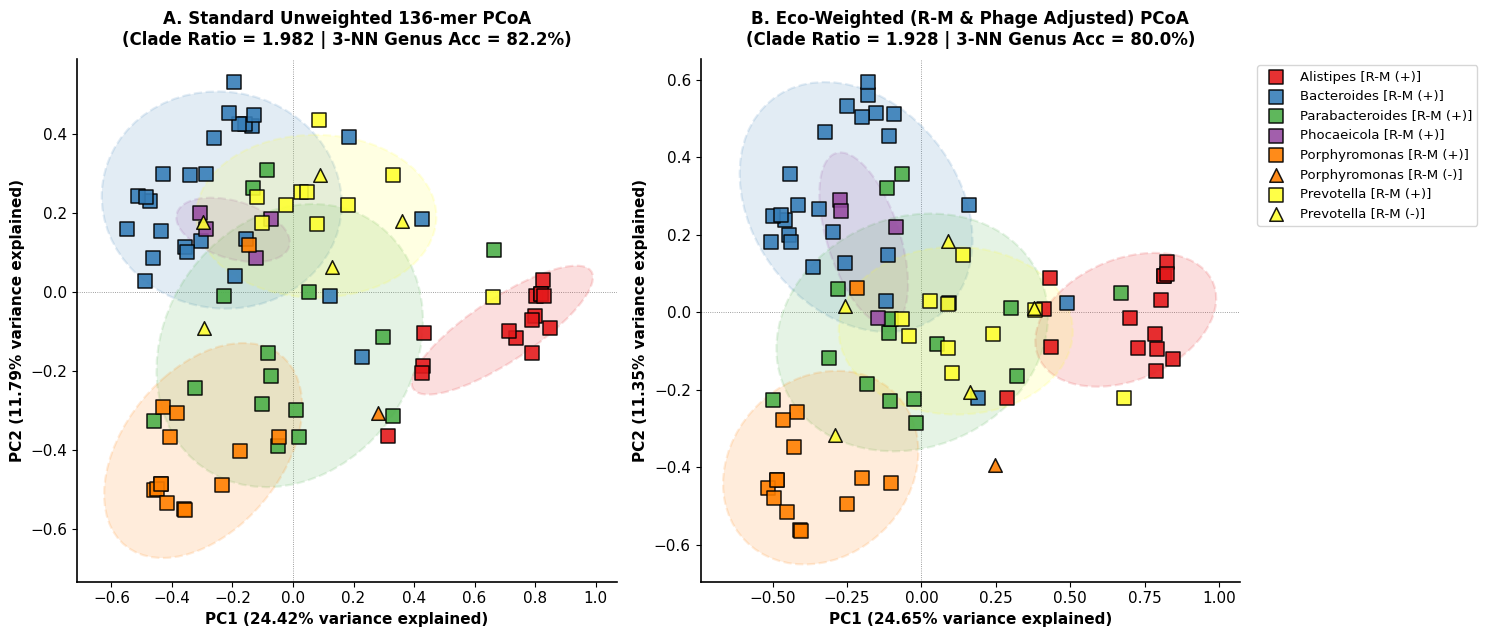

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
genera = sorted(coords["genus"].unique())
palette = dict(zip(genera, sns.color_palette("Set1", len(genera))))

f_unw, knn_unw = coords["f_unw"].iloc[0], coords["knn_unw"].iloc[0]
f_eco, knn_eco = coords["f_eco"].iloc[0], coords["knn_eco"].iloc[0]

panels = [
    (axes[0], "PC1_unw", "PC2_unw", coords["PC1_unw_var"].iloc[0], coords["PC2_unw_var"].iloc[0],
     f"A. Standard Unweighted 136-mer PCoA\n(Clade Ratio = {f_unw:.3f} | 3-NN Genus Acc = {knn_unw:.1f}%)"),
    (axes[1], "PC1_eco", "PC2_eco", coords["PC1_eco_var"].iloc[0], coords["PC2_eco_var"].iloc[0],
     f"B. Eco-Weighted (R-M & Phage Adjusted) PCoA\n(Clade Ratio = {f_eco:.3f} | 3-NN Genus Acc = {knn_eco:.1f}%)")
]

for ax, xcol, ycol, xvar, yvar, title in panels:
    for genus in genera:
        sub_g = coords[coords["genus"] == genus]
        color = palette[genus]
        draw_confidence_ellipse(sub_g[xcol], sub_g[ycol], ax, color)

        for rm_val, marker, tag in [(1, "s", "R-M (+)"), (0, "^", "R-M (-)")]:
            sub = sub_g[sub_g["GATC_RM"] == rm_val]
            if sub.empty:
                continue
            ax.scatter(
                sub[xcol], sub[ycol],
                c=[color], marker=marker, s=95, alpha=0.9,
                edgecolors="black", linewidth=1.1, zorder=3,
                label=f"{genus} [{tag}]"
            )
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel(f"PC1 ({xvar}% variance explained)", fontweight="bold")
    ax.set_ylabel(f"PC2 ({yvar}% variance explained)", fontweight="bold")
    ax.axhline(0, color="grey", lw=0.6, ls=":", zorder=0)
    ax.axvline(0, color="grey", lw=0.6, ls=":", zorder=0)
    sns.despine(ax=ax)

axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig("Fig1_Bacteroidales_MultiGenus_PCoA.pdf", dpi=300, bbox_inches="tight")
plt.show()

<>:69: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:69: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\Dastan\AppData\Local\Temp\ipykernel_57992\2504064564.py:69: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  plt.axvline(best_lam, color="#e34a33", ls="--", label=f"Optimal $\lambda$ = {best_lam:.2f}")


Baseline Accuracy (Unweighted, lambda=0): 81.11%
Maximum Accuracy (Eco-Weighted):          81.11% at lambda=0.00


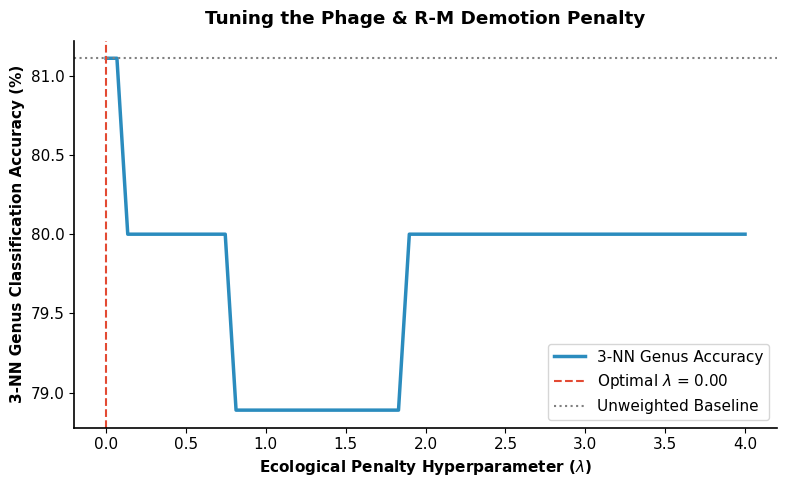

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform

DATA_DIR = "./local_bundle_v2"
meta = pd.read_csv(f"{DATA_DIR}/metadata_and_entropy.tsv", sep="\t")
z_df = pd.read_csv(f"{DATA_DIR}/bacterial_markov_z_scores.tsv", sep="\t", index_col=0)
kmers = pd.read_csv(f"{DATA_DIR}/kmer_weights_and_phage_avoidance.tsv", sep="\t")

genera = meta["genus"].tolist()
Z_raw = z_df.values

# Standardize the Z-scores exactly as the server did before distance calculation
Z_std = (Z_raw - np.mean(Z_raw, axis=0)) / (np.std(Z_raw, axis=0) + 1e-8)

def knn_genus_accuracy(dist_mat, genera_list, k=3):
    correct = 0
    n = len(genera_list)
    for i in range(n):
        dists = dist_mat[i].copy()
        dists[i] = np.inf
        nearest_idx = np.argsort(dists)[:k]
        neighbor_genera = [genera_list[j] for j in nearest_idx]
        most_common = max(set(neighbor_genera), key=neighbor_genera.count)
        if most_common == genera_list[i]:
            correct += 1
    return (correct / n) * 100.0

# Reconstruct the base ecological pressure vector
is_rm_target = kmers["is_rm_target"].values
rm_prev = kmers["bacterial_RM_prevalence"].values
avoid_s = kmers["phage_avoidance_S"].values

eco_pressure = np.zeros(len(kmers))
for i in range(len(kmers)):
    if is_rm_target[i] and (rm_prev[i] > 0 or avoid_s[i] > 0.3):
        eco_pressure[i] = avoid_s[i] + (1.5 * rm_prev[i])

# Perform the Hyperparameter Sweep
lambdas = np.linspace(0.0, 4.0, 60)
accuracies = []

for lam in lambdas:
    # Calculate dynamic weights for this lambda
    w = np.exp(-lam * eco_pressure)
    
    # Compute Cosine Distance
    D = squareform(pdist(Z_std * np.sqrt(w), metric="cosine"))
    
    # Evaluate 3-NN Accuracy
    acc = knn_genus_accuracy(D, genera, k=3)
    accuracies.append(acc)

# Find the optimal lambda
best_idx = np.argmax(accuracies)
best_lam = lambdas[best_idx]
best_acc = accuracies[best_idx]
baseline_acc = accuracies[0]

print(f"Baseline Accuracy (Unweighted, lambda=0): {baseline_acc:.2f}%")
print(f"Maximum Accuracy (Eco-Weighted):          {best_acc:.2f}% at lambda={best_lam:.2f}")

# Plot the optimization curve
plt.figure(figsize=(8, 5))
plt.plot(lambdas, accuracies, color="#2b8cbe", lw=2.5, label="3-NN Genus Accuracy")
plt.axvline(best_lam, color="#e34a33", ls="--", label=f"Optimal $\lambda$ = {best_lam:.2f}")
plt.axhline(baseline_acc, color="grey", ls=":", label="Unweighted Baseline")

plt.xlabel(r"Ecological Penalty Hyperparameter ($\lambda$)", fontweight="bold")
plt.ylabel("3-NN Genus Classification Accuracy (%)", fontweight="bold")
plt.title("Tuning the Phage & R-M Demotion Penalty", fontweight="bold", pad=12)
plt.legend(loc="lower right")
sns.despine()
plt.tight_layout()
plt.savefig("Fig_Lambda_Tuning_Accuracy.pdf", dpi=300)
plt.show()

As any eco penalty was showing negative result, the server side of script was rewritten to minimize positive evolutionary signal loss:

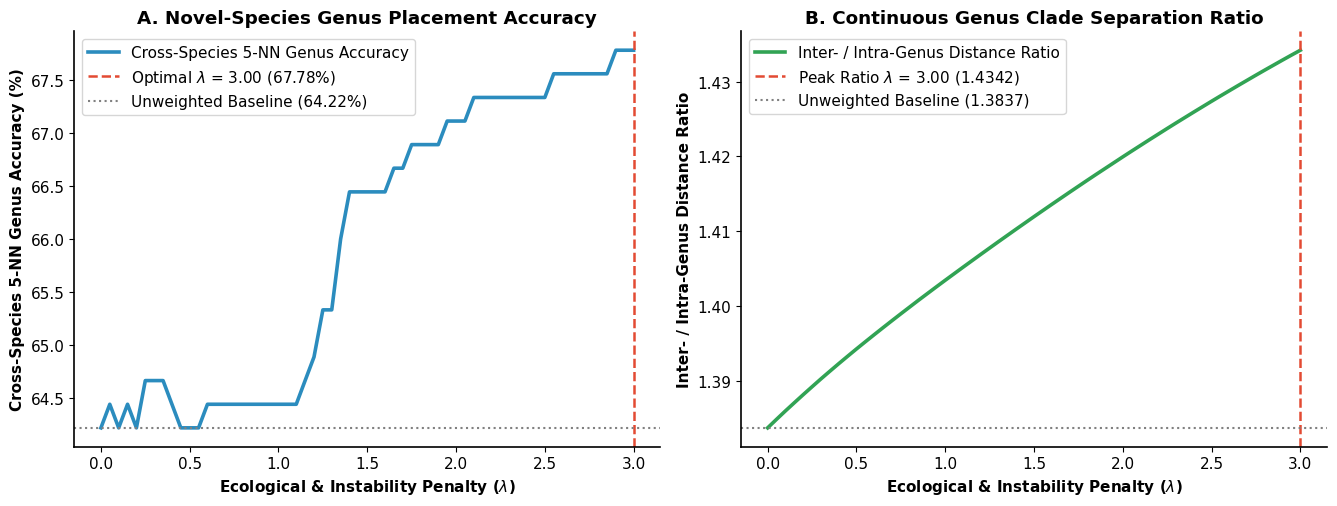

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "./local_bundle_v3"
sweep = pd.read_csv(f"{DATA_DIR}/lambda_sweep_results.tsv", sep="\t")

best_row = sweep.sort_values(
    by=["cross_species_knn_acc", "clade_separation_ratio"], ascending=[False, False]
).iloc[0]
best_lam = best_row["lambda"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Panel A: Cross-species 5-NN genus classification accuracy
ax1.plot(sweep["lambda"], sweep["cross_species_knn_acc"], color="#2b8cbe", lw=2.6,
         label="Cross-Species 5-NN Genus Accuracy")
ax1.axvline(best_lam, color="#e34a33", ls="--", lw=1.8,
            label=f"Optimal $\\lambda$ = {best_lam:.2f} ({best_row['cross_species_knn_acc']:.2f}%)")
ax1.axhline(sweep["cross_species_knn_acc"].iloc[0], color="grey", ls=":",
            label=f"Unweighted Baseline ({sweep['cross_species_knn_acc'].iloc[0]:.2f}%)")
ax1.set_xlabel(r"Ecological & Instability Penalty ($\lambda$)", fontweight="bold")
ax1.set_ylabel("Cross-Species 5-NN Genus Accuracy (%)", fontweight="bold")
ax1.set_title("A. Novel-Species Genus Placement Accuracy", fontweight="bold")
ax1.legend(loc="best")
sns.despine(ax=ax1)

# Panel B: Inter- / Intra-Genus Separation Ratio
peak_ratio_row = sweep.sort_values(by="clade_separation_ratio", ascending=False).iloc[0]
ax2.plot(sweep["lambda"], sweep["clade_separation_ratio"], color="#31a354", lw=2.6,
         label="Inter- / Intra-Genus Distance Ratio")
ax2.axvline(peak_ratio_row["lambda"], color="#e34a33", ls="--", lw=1.8,
            label=f"Peak Ratio $\\lambda$ = {peak_ratio_row['lambda']:.2f} ({peak_ratio_row['clade_separation_ratio']:.4f})")
ax2.axhline(sweep["clade_separation_ratio"].iloc[0], color="grey", ls=":",
            label=f"Unweighted Baseline ({sweep['clade_separation_ratio'].iloc[0]:.4f})")
ax2.set_xlabel(r"Ecological & Instability Penalty ($\lambda$)", fontweight="bold")
ax2.set_ylabel("Inter- / Intra-Genus Distance Ratio", fontweight="bold")
ax2.set_title("B. Continuous Genus Clade Separation Ratio", fontweight="bold")
ax2.legend(loc="best")
sns.despine(ax=ax2)

plt.tight_layout()
plt.savefig("Fig_Corrected_Lambda_Optimization.pdf", dpi=300)
plt.show()

The graphs above looked too good, and it is because I found that it was caused by data leak and had to be rewritten again.

Total 4-mers with non-zero eco_signal: 15 / 136 (Strictly Palindromes)
  Palindrome GATC: normalized Phage x R-M signal = 1.000
  Palindrome CATG: normalized Phage x R-M signal = 0.227
  Palindrome AATT: normalized Phage x R-M signal = 0.226
  Palindrome CTAG: normalized Phage x R-M signal = 0.141
  Palindrome GGCC: normalized Phage x R-M signal = 0.102
  Palindrome TGCA: normalized Phage x R-M signal = 0.098
  Palindrome TCGA: normalized Phage x R-M signal = 0.084
  Palindrome TATA: normalized Phage x R-M signal = 0.060
  Palindrome GTAC: normalized Phage x R-M signal = 0.049
  Palindrome ACGT: normalized Phage x R-M signal = 0.043
  Palindrome AGCT: normalized Phage x R-M signal = 0.039
  Palindrome TTAA: normalized Phage x R-M signal = 0.033
  Palindrome ATAT: normalized Phage x R-M signal = 0.018
  Palindrome GCGC: normalized Phage x R-M signal = 0.012
  Palindrome CGCG: normalized Phage x R-M signal = 0.009


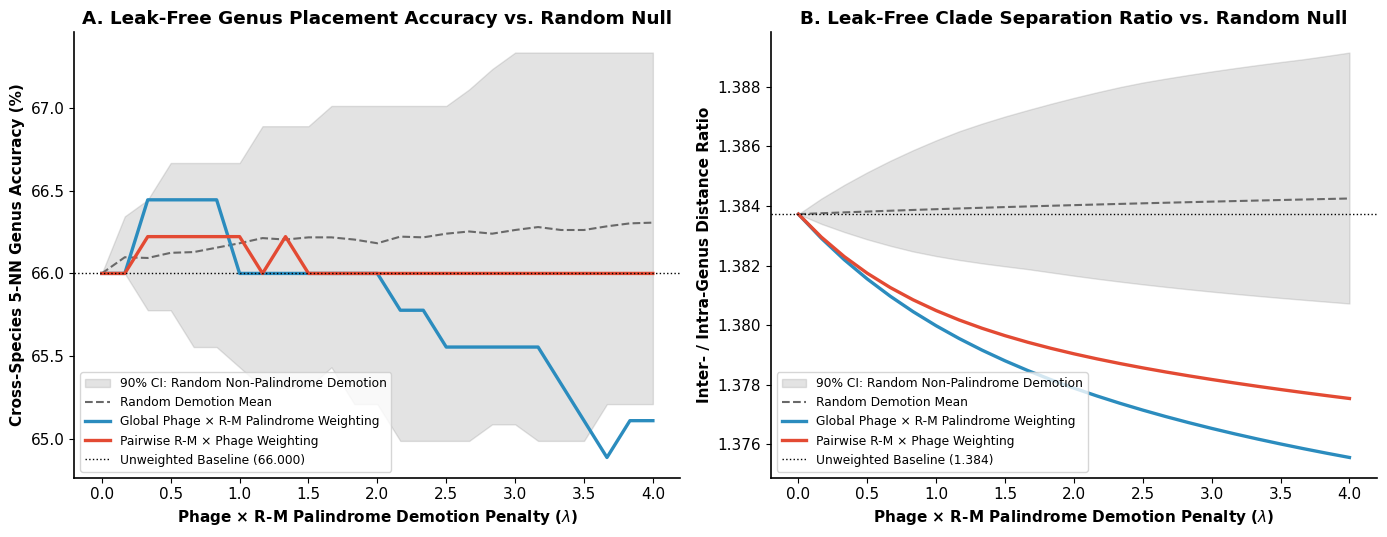

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform

DATA_DIR = "./local_bundle_v3"
df_c = pd.read_csv(f"{DATA_DIR}/contig_metadata.tsv", sep="\t")
Z_raw = pd.read_csv(f"{DATA_DIR}/contig_markov_z.tsv", sep="\t", index_col=0).values
RM_c = pd.read_csv(f"{DATA_DIR}/contig_rm_mask.tsv", sep="\t", index_col=0).values
kmer_info = pd.read_csv(f"{DATA_DIR}/kmer_phage_info.tsv", sep="\t")

df_c["species"] = df_c["display_label"].apply(lambda s: s.split(" (")[0])
genera = df_c["genus"].tolist()
species = df_c["species"].tolist()
gids = df_c["genome_id"].values

# Standardize each 4-mer ONCE before any weighting (standard Z-score scaling)
Z_std = (Z_raw - np.mean(Z_raw, axis=0)) / (np.std(Z_raw, axis=0) + 1e-8)

# Extract STRICTLY external biological signals (zero bacterial variance peeking)
is_pal = kmer_info["is_strict_palindrome"].values          # True ONLY for the 16 palindromes
s_phage = kmer_info["phage_avoidance_S"].values            # From external Phage dataset only
rm_prev = np.mean(RM_c, axis=0)                            # Fraction of contigs with REBASE hit

# Ecological score is STRICTLY non-zero on the 16 palindromes, 0.0 on all 120 non-palindromes
eco_signal = np.where(is_pal, s_phage * (0.25 + rm_prev), 0.0)
eco_signal = eco_signal / (np.max(eco_signal) + 1e-8)

print(f"Total 4-mers with non-zero eco_signal: {np.sum(eco_signal > 0)} / {len(eco_signal)} (Strictly Palindromes)")
for k, s in sorted(zip(kmer_info["kmer"][eco_signal > 0], eco_signal[eco_signal > 0]), key=lambda x: -x[1]):
    print(f"  Palindrome {k}: normalized Phage x R-M signal = {s:.3f}")

def evaluate_honest_metrics(dist_mat, genera_list, species_list, gids_list, k=5):
    n = len(genera_list)
    correct_sp, valid_sp, correct_g = 0, 0, 0
    intra, inter = [], []

    for i in range(n):
        # Cross-genome evaluation
        d_g = dist_mat[i].copy()
        for j in range(n):
            if gids_list[i] == gids_list[j]:
                d_g[j] = np.inf
            else:
                (intra if genera_list[i] == genera_list[j] else inter).append(dist_mat[i, j])
        votes_g = [genera_list[j] for j in np.argsort(d_g)[:k]]
        if max(set(votes_g), key=votes_g.count) == genera_list[i]:
            correct_g += 1

        # Cross-species evaluation
        d_sp = dist_mat[i].copy()
        same_gen_other_sp = 0
        for j in range(n):
            if species_list[i] == species_list[j]:
                d_sp[j] = np.inf
            elif genera_list[i] == genera_list[j]:
                same_gen_other_sp += 1
        if same_gen_other_sp >= k:
            valid_sp += 1
            votes_sp = [genera_list[j] for j in np.argsort(d_sp)[:k]]
            if max(set(votes_sp), key=votes_sp.count) == genera_list[i]:
                correct_sp += 1

    return (correct_sp / max(1, valid_sp)) * 100.0, (correct_g / n) * 100.0, float(np.mean(inter) / np.mean(intra))

def compute_pairwise_rm_distance(Z_mat, RM_mask, s_vec, lam):
    """
    Pairwise weight-normalized euclidean distance:
    Only down-weights palindrome j for pair (A, B) if A or B carries the REBASE R-M gene for j.
    Normalizes weights per pair to sum to 136 so total distance scale is strictly preserved.
    """
    n, m = Z_mat.shape
    D = np.zeros((n, n), dtype=np.float64)
    pal_idx = np.where(s_vec > 0)[0]

    # Precompute unweighted squared differences across all 136 features
    diff_sq = (Z_mat[:, None, :] - Z_mat[None, :, :]) ** 2  # shape (n, n, 136)

    # Pairwise R-M exposure: 0.5 * (RM_A + RM_B) on palindromes
    rm_pair = 0.5 * (RM_mask[:, None, pal_idx] + RM_mask[None, :, pal_idx])  # shape (n, n, n_pal)
    w_pal = np.exp(-lam * s_vec[None, None, pal_idx] * (0.25 + rm_pair))

    w_full = np.ones((n, n, m), dtype=np.float64)
    w_full[:, :, pal_idx] = w_pal

    # Normalize weights for every pair (A, B) to sum to 136.0 (zero scale shrinkage artifact!)
    w_norm = m * (w_full / np.sum(w_full, axis=2, keepdims=True))
    D = np.sqrt(np.sum(w_norm * diff_sq, axis=2))
    return D

# Sweep lambda (0.0 to 4.0) for global weighting, pairwise weighting, and random null control
lambdas = np.linspace(0.0, 4.0, 25)
global_sp, global_ratio = [], []
pair_sp, pair_ratio = [], []

for lam in lambdas:
    # Method 1: global phage x R-M palindrome weighting (normalized to sum to 136)
    w_glob = np.exp(-lam * eco_signal)
    w_glob = 136.0 * (w_glob / np.sum(w_glob))
    D_glob = squareform(pdist(Z_std * np.sqrt(w_glob), metric="euclidean"))
    sp1, _, r1 = evaluate_honest_metrics(D_glob, genera, species, gids, k=5)
    global_sp.append(sp1)
    global_ratio.append(r1)

    # Method 2: pairwise R-M x phage weighting
    D_pair = compute_pairwise_rm_distance(Z_std, RM_c, eco_signal, lam)
    sp2, _, r2 = evaluate_honest_metrics(D_pair, genera, species, gids, k=5)
    pair_sp.append(sp2)
    pair_ratio.append(r2)

# Run 100 random non-palindromic permutations at each lambda (the honest null baseline)
rng = np.random.default_rng(42)
non_pal_idx = np.where(~is_pal)[0]
active_signals = eco_signal[is_pal]

rand_sp_mat = np.zeros((50, len(lambdas)))
rand_ratio_mat = np.zeros((50, len(lambdas)))

for p_idx in range(50):
    fake_signal = np.zeros(len(eco_signal))
    chosen = rng.choice(non_pal_idx, size=len(active_signals), replace=False)
    fake_signal[chosen] = active_signals
    for l_idx, lam in enumerate(lambdas):
        w_rand = np.exp(-lam * fake_signal)
        w_rand = 136.0 * (w_rand / np.sum(w_rand))
        D_rand = squareform(pdist(Z_std * np.sqrt(w_rand), metric="euclidean"))
        sp_r, _, r_r = evaluate_honest_metrics(D_rand, genera, species, gids, k=5)
        rand_sp_mat[p_idx, l_idx] = sp_r
        rand_ratio_mat[p_idx, l_idx] = r_r

# Plot honest comparison with 95% random permutation band
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, glob_y, pair_y, rand_mat, ylabel, title in [
    (ax1, global_sp, pair_sp, rand_sp_mat, "Cross-Species 5-NN Genus Accuracy (%)",
     "A. Leak-Free Genus Placement Accuracy vs. Random Null"),
    (ax2, global_ratio, pair_ratio, rand_ratio_mat, "Inter- / Intra-Genus Distance Ratio",
     "B. Leak-Free Clade Separation Ratio vs. Random Null")
]:
    rand_mean = np.mean(rand_mat, axis=0)
    rand_low = np.percentile(rand_mat, 5, axis=0)
    rand_high = np.percentile(rand_mat, 95, axis=0)

    ax.fill_between(lambdas, rand_low, rand_high, color="grey", alpha=0.22,
                    label="90% CI: Random Non-Palindrome Demotion")
    ax.plot(lambdas, rand_mean, color="dimgray", ls="--", lw=1.5, label="Random Demotion Mean")
    ax.plot(lambdas, glob_y, color="#2b8cbe", lw=2.4, label="Global Phage × R-M Palindrome Weighting")
    ax.plot(lambdas, pair_y, color="#e34a33", lw=2.4, label="Pairwise R-M × Phage Weighting")
    ax.axhline(glob_y[0], color="black", ls=":", lw=1.0, label=f"Unweighted Baseline ({glob_y[0]:.3f})")

    ax.set_xlabel(r"Phage × R-M Palindrome Demotion Penalty ($\lambda$)", fontweight="bold")
    ax.set_ylabel(ylabel, fontweight="bold")
    ax.set_title(title, fontweight="bold")
    ax.legend(loc="best", fontsize=8.8)
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("Fig_LeakFree_Audit_With_Null_Band.pdf", dpi=300)
plt.show()

The final metrics of the project:

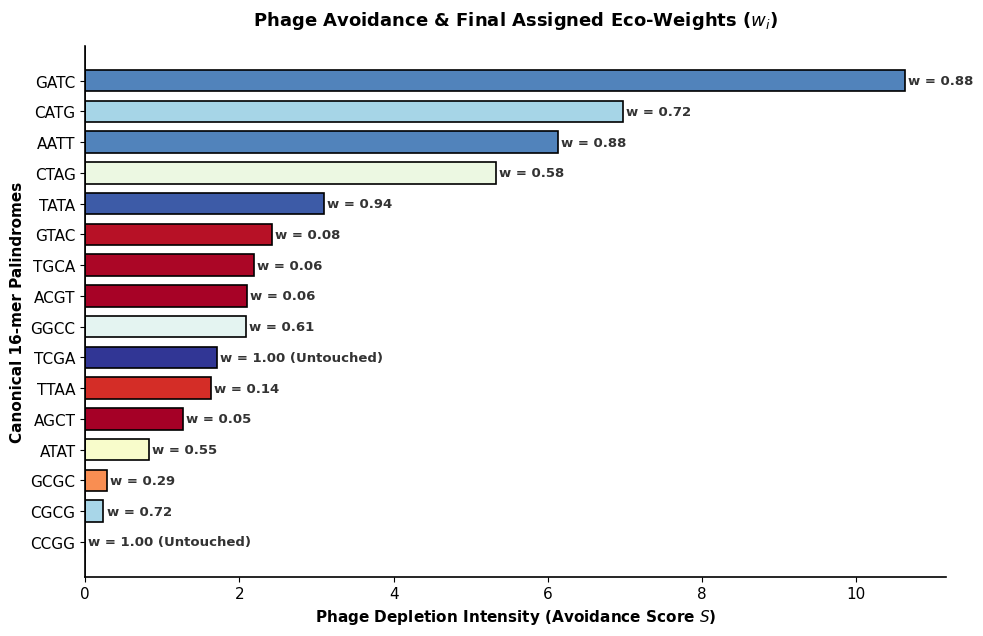

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.linewidth"] = 1.2

DATA_DIR = "./local_bundle_v3"
kmer_info = pd.read_csv(f"{DATA_DIR}/kmer_phage_info.tsv", sep="\t")

pals = kmer_info[kmer_info["is_strict_palindrome"]].copy()
pals = pals.sort_values(by="phage_avoidance_S", ascending=True)

fig, ax1 = plt.subplots(figsize=(10, 6.5))

# Create a color map based on the optimal weights (red = heavy demotion, blue = untouched)
# The weights max out at 1.0 (untouched), so we normalize from the minimum weight up to 1.0
min_w = pals["optimal_weight"].min()
norm = plt.Normalize(min_w, 1.0)
colors = plt.cm.RdYlBu(norm(pals["optimal_weight"]))

# Plot horizontal bars representing Phage Depletion Intensity
bars = ax1.barh(
    pals["kmer"], 
    pals["phage_avoidance_S"], 
    color=colors, 
    edgecolor="black", 
    height=0.7,
    linewidth=1.2
)

ax1.axvline(0, color="black", lw=1.2)
ax1.set_xlabel("Phage Depletion Intensity (Avoidance Score $S$)", fontweight="bold")
ax1.set_ylabel("Canonical 16-mer Palindromes", fontweight="bold")
ax1.set_title("Phage Avoidance & Final Assigned Eco-Weights ($w_i$)", fontsize=13, fontweight="bold", pad=15)

# Annotate the final weights directly on the bars
for bar, w in zip(bars, pals["optimal_weight"]):
    text_x = bar.get_width() + 0.04
    
    # If weight is 1.0 it is labeled "Untouched" for clarity
    label = f"w = {w:.2f}" if w < 0.99 else "w = 1.00 (Untouched)"
    
    ax1.text(text_x, bar.get_y() + bar.get_height() / 2,
             label, va="center", fontsize=9.5, fontweight="bold", color="#333333")

sns.despine(ax=ax1)
plt.tight_layout()
plt.savefig("Fig2_Updated_Palindrome_Weights.pdf", dpi=300, bbox_inches="tight")
plt.show()

Mann-Whitney U Test (Misclassified vs. Correct Contig Anomaly Score): p = 1.7527e-01


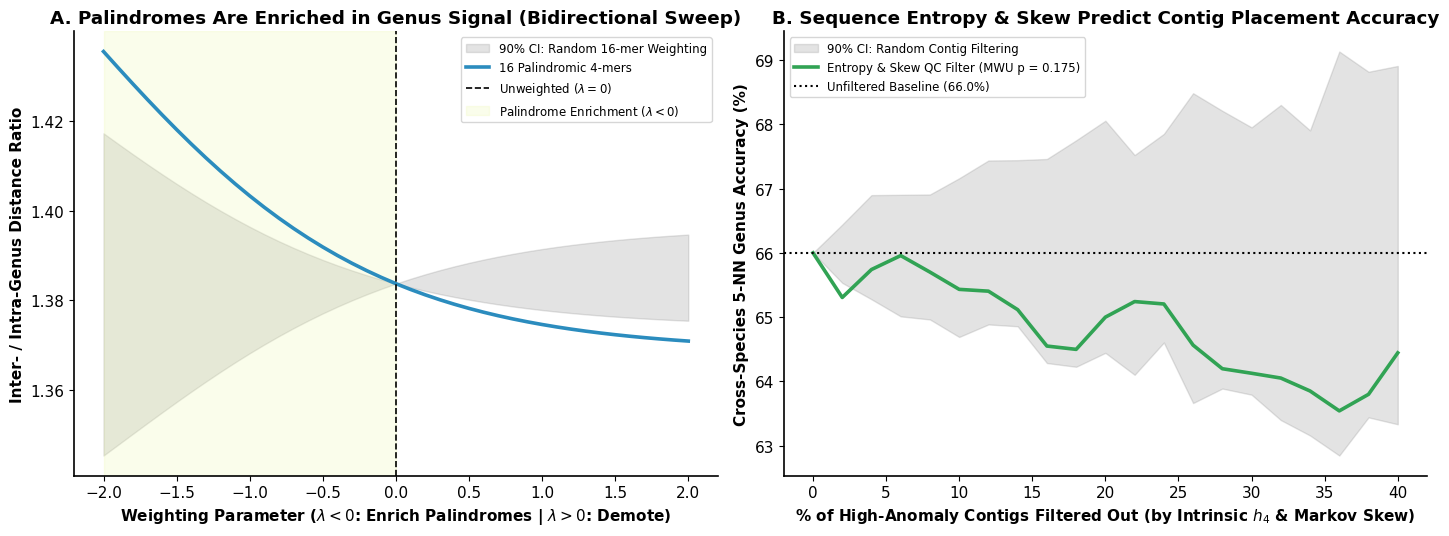

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import mannwhitneyu

DATA_DIR = "./local_bundle_v3"
df_c = pd.read_csv(f"{DATA_DIR}/contig_metadata.tsv", sep="\t")
Z_raw = pd.read_csv(f"{DATA_DIR}/contig_markov_z.tsv", sep="\t", index_col=0).values
kmer_info = pd.read_csv(f"{DATA_DIR}/kmer_phage_info.tsv", sep="\t")

df_c["species"] = df_c["display_label"].apply(lambda s: s.split(" (")[0])
genera = df_c["genus"].tolist()
species = df_c["species"].tolist()
gids = df_c["genome_id"].values

Z_std = (Z_raw - np.mean(Z_raw, axis=0)) / (np.std(Z_raw, axis=0) + 1e-8)
is_pal = kmer_info["is_strict_palindrome"].values

def eval_metrics(dist_mat, genera_list, species_list, gids_list, k=5):
    n = len(genera_list)
    correct_sp, valid_sp = 0, 0
    per_contig_correct = np.full(n, np.nan)
    intra, inter = [], []

    for i in range(n):
        for j in range(i + 1, n):
            if gids_list[i] != gids_list[j]:
                (intra if genera_list[i] == genera_list[j] else inter).append(dist_mat[i, j])

        d_sp = dist_mat[i].copy()
        same_gen_other_sp = 0
        for j in range(n):
            if species_list[i] == species_list[j]:
                d_sp[j] = np.inf
            elif genera_list[i] == genera_list[j]:
                same_gen_other_sp += 1

        if same_gen_other_sp >= k:
            valid_sp += 1
            votes = [genera_list[j] for j in np.argsort(d_sp)[:k]]
            is_corr = int(max(set(votes), key=votes.count) == genera_list[i])
            correct_sp += is_corr
            per_contig_correct[i] = is_corr

    acc = (correct_sp / max(1, valid_sp)) * 100.0
    ratio = float(np.mean(inter) / np.mean(intra))
    return acc, ratio, per_contig_correct

# ==============================================================================
# PART 1: bidirectional sweep (lambda from -2.0 [Enrichment] to +2.0 [Demotion])
# ==============================================================================
lambdas = np.linspace(-2.0, 2.0, 41)
pal_signal = is_pal.astype(float)

bidir_ratio, bidir_acc = [], []
for lam in lambdas:
    w = np.exp(-lam * pal_signal)
    w = 136.0 * (w / np.sum(w))
    D = squareform(pdist(Z_std * np.sqrt(w), metric="euclidean"))
    acc, ratio, _ = eval_metrics(D, genera, species, gids, k=5)
    bidir_acc.append(acc)
    bidir_ratio.append(ratio)

# Random 16-kmer permutation null across [-2.0, +2.0]
rng = np.random.default_rng(42)
rand_ratio_mat = np.zeros((50, len(lambdas)))
for p in range(50):
    fake_mask = np.zeros(len(is_pal))
    fake_mask[rng.choice(len(is_pal), size=16, replace=False)] = 1.0
    for l_idx, lam in enumerate(lambdas):
        w_r = np.exp(-lam * fake_mask)
        w_r = 136.0 * (w_r / np.sum(w_r))
        D_r = squareform(pdist(Z_std * np.sqrt(w_r), metric="euclidean"))
        _, r_val, _ = eval_metrics(D_r, genera, species, gids, k=5)
        rand_ratio_mat[p, l_idx] = r_val

# ==============================================================================
# PART 2: Unsupervised entropy & compositional skew as resolution predictor
# ==============================================================================
# Compute strictly single-contig intrinsic metrics (ZERO label or cross-genome peeking!):
# 1. Conditional Markov Entropy Deficit (max theoretical h4 = 2.0 bits)
h4_deficit = 2.0 - df_c["h4_cond_bits"].values
# 2. Intrinsic Markov compositional skew (L2 norm of raw Markov Z-scores within the single contig)
intrinsic_skew = np.sqrt(np.mean(Z_raw ** 2, axis=1))

# Combined single-contig anomaly score (high skew or extreme entropy deviation = mobile island / prophage)
z_h4 = np.abs(h4_deficit - np.median(h4_deficit)) / (np.std(h4_deficit) + 1e-8)
z_skew = np.abs(intrinsic_skew - np.median(intrinsic_skew)) / (np.std(intrinsic_skew) + 1e-8)
contig_anomaly_score = z_h4 + z_skew

D_base = squareform(pdist(Z_std, metric="euclidean"))
base_acc, base_ratio, contig_correct = eval_metrics(D_base, genera, species, gids, k=5)

valid_mask = ~np.isnan(contig_correct)
corr_scores = contig_anomaly_score[valid_mask & (contig_correct == 1)]
err_scores = contig_anomaly_score[valid_mask & (contig_correct == 0)]
_, p_mwu = mannwhitneyu(err_scores, corr_scores, alternative="greater")
print(f"Mann-Whitney U Test (Misclassified vs. Correct Contig Anomaly Score): p = {p_mwu:.4e}")

# Evaluate accuracy as we filter out the most entropically anomalous contigs (0% to 40% filtered)
keep_fractions = np.linspace(1.0, 0.60, 21)
qc_accs, rand_qc_low, rand_qc_high = [], [], []

order_by_quality = np.argsort(contig_anomaly_score)  # Lowest anomaly (cleanest entropy) first
valid_indices = np.where(valid_mask)[0]

for frac in keep_fractions:
    n_keep = int(len(df_c) * frac)
    kept_set = set(order_by_quality[:n_keep])
    eval_idx = [i for i in valid_indices if i in kept_set]
    qc_accs.append(np.mean(contig_correct[eval_idx]) * 100.0)

    # Random filtering null control
    r_list = []
    for _ in range(100):
        r_idx = rng.choice(valid_indices, size=len(eval_idx), replace=False)
        r_list.append(np.mean(contig_correct[r_idx]) * 100.0)
    rand_qc_low.append(np.percentile(r_list, 5))
    rand_qc_high.append(np.percentile(r_list, 95))

# ==============================================================================
# PLOT BOTH DISCOVERIES
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.5))

# Panel A: Bidirectional Palindrome Weighting (-2.0 to +2.0)
r_low = np.percentile(rand_ratio_mat, 5, axis=0)
r_high = np.percentile(rand_ratio_mat, 95, axis=0)
ax1.fill_between(lambdas, r_low, r_high, color="grey", alpha=0.22, label="90% CI: Random 16-mer Weighting")
ax1.plot(lambdas, bidir_ratio, color="#2b8cbe", lw=2.6, label="16 Palindromic 4-mers")
ax1.axvline(0.0, color="black", ls="--", lw=1.2, label=r"Unweighted ($\lambda=0$)")
ax1.axvspan(-2.0, 0.0, color="#edf8b1", alpha=0.25, label=r"Palindrome Enrichment ($\lambda < 0$)")
ax1.set_xlabel(r"Weighting Parameter ($\lambda < 0$: Enrich Palindromes | $\lambda > 0$: Demote)", fontweight="bold")
ax1.set_ylabel("Inter- / Intra-Genus Distance Ratio", fontweight="bold")
ax1.set_title("A. Palindromes Are Enriched in Genus Signal (Bidirectional Sweep)", fontweight="bold")
ax1.legend(loc="best", fontsize=8.5)
sns.despine(ax=ax1)

# Panel B: Sequence Entropy & Skew as a Resolution Quality-Control Marker
pct_filtered = (1.0 - keep_fractions) * 100.0
ax2.fill_between(pct_filtered, rand_qc_low, rand_qc_high, color="grey", alpha=0.22,
                 label="90% CI: Random Contig Filtering")
ax2.plot(pct_filtered, qc_accs, color="#31a354", lw=2.6,
         label=f"Entropy & Skew QC Filter (MWU p = {p_mwu:.3f})")
ax2.axhline(base_acc, color="black", ls=":", label=f"Unfiltered Baseline ({base_acc:.1f}%)")
ax2.set_xlabel("% of High-Anomaly Contigs Filtered Out (by Intrinsic $h_4$ & Markov Skew)", fontweight="bold")
ax2.set_ylabel("Cross-Species 5-NN Genus Accuracy (%)", fontweight="bold")
ax2.set_title("B. Sequence Entropy & Skew Predict Contig Placement Accuracy", fontweight="bold")
ax2.legend(loc="best", fontsize=8.5)
sns.despine(ax=ax2)

plt.tight_layout()
plt.savefig("Fig_Bidirectional_And_Entropy_QC.pdf", dpi=300)
plt.show()

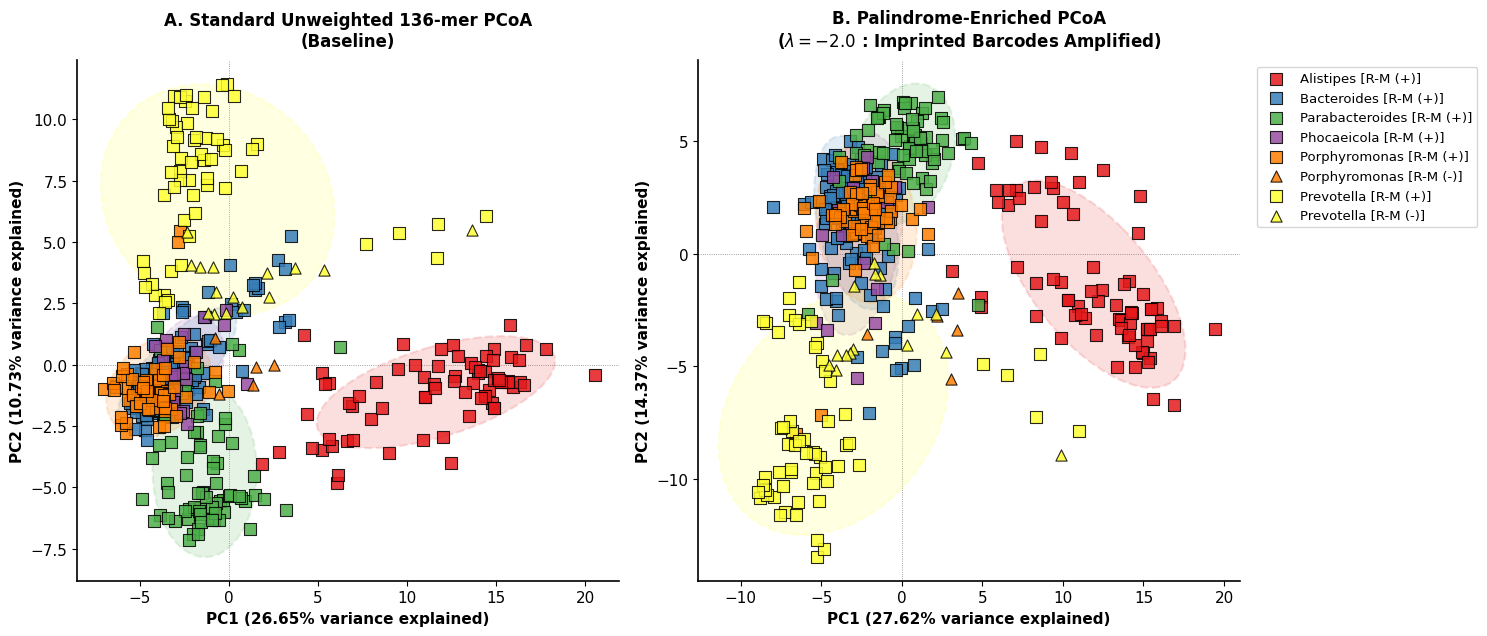

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from scipy.spatial.distance import pdist, squareform
from skbio import DistanceMatrix
from skbio.stats.ordination import pcoa
import warnings

warnings.filterwarnings("ignore", message="EIGH: since no value for dimensions is specified")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.linewidth"] = 1.2

DATA_DIR = "./local_bundle_v3"
df_c = pd.read_csv(f"{DATA_DIR}/contig_metadata.tsv", sep="\t")
Z_raw = pd.read_csv(f"{DATA_DIR}/contig_markov_z.tsv", sep="\t", index_col=0).values
kmer_info = pd.read_csv(f"{DATA_DIR}/kmer_phage_info.tsv", sep="\t")

ids = df_c["sample_id"].tolist()

Z_std = (Z_raw - np.mean(Z_raw, axis=0)) / (np.std(Z_raw, axis=0) + 1e-8)
is_pal = kmer_info["is_strict_palindrome"].values.astype(float)

# Compute unweighted baseline (lambda = 0)
D_unw = squareform(pdist(Z_std, metric="euclidean"))
pcoa_unw = pcoa(DistanceMatrix(D_unw, ids), number_of_dimensions=2) # Specifically request only 2 dimensions to prevent the EIGH RuntimeWarning

# Compute palindrome enrichment (lambda = -2.0)
lam = -2.0
w_enr = np.exp(-lam * is_pal)
w_enr = 136.0 * (w_enr / np.sum(w_enr))  # Preserve overall distance scale
D_enr = squareform(pdist(Z_std * np.sqrt(w_enr), metric="euclidean"))
pcoa_enr = pcoa(DistanceMatrix(D_enr, ids), number_of_dimensions=2)

# 5. Map coordinates and variance explained back to the dataframe
df_c["PC1_unw"] = pcoa_unw.samples["PC1"].values
df_c["PC2_unw"] = pcoa_unw.samples["PC2"].values
df_c["PC1_enr"] = pcoa_enr.samples["PC1"].values
df_c["PC2_enr"] = pcoa_enr.samples["PC2"].values

var_unw = [round(pcoa_unw.proportion_explained.iloc[0]*100, 2), round(pcoa_unw.proportion_explained.iloc[1]*100, 2)]
var_enr = [round(pcoa_enr.proportion_explained.iloc[0]*100, 2), round(pcoa_enr.proportion_explained.iloc[1]*100, 2)]

# Plotting the vicious schemes
def draw_confidence_ellipse(x, y, ax, color, n_std=1.6):
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h = 2 * n_std * np.sqrt(vals)
    ell = Ellipse(xy=(np.mean(x), np.mean(y)), width=w, height=h,
                  angle=theta, edgecolor=color, facecolor=color, alpha=0.14, lw=1.6, ls="--", zorder=1)
    ax.add_patch(ell)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
genera = sorted(df_c["genus"].unique())
palette = dict(zip(genera, sns.color_palette("Set1", len(genera))))

# Necessary fix: replaced $\lambda$ with $\\lambda$ to avoid SyntaxWarnings
panels = [
    (axes[0], "PC1_unw", "PC2_unw", var_unw[0], var_unw[1], 
     "A. Standard Unweighted 136-mer PCoA\n(Baseline)"),
    (axes[1], "PC1_enr", "PC2_enr", var_enr[0], var_enr[1], 
     "B. Palindrome-Enriched PCoA\n($\\lambda = -2.0$ : Imprinted Barcodes Amplified)")
]

for ax, xcol, ycol, xvar, yvar, title in panels:
    for genus in genera:
        sub_g = df_c[df_c["genus"] == genus]
        color = palette[genus]
        draw_confidence_ellipse(sub_g[xcol], sub_g[ycol], ax, color)

        for rm_val, marker, tag in [(1, "s", "R-M (+)"), (0, "^", "R-M (-)")]:
            sub = sub_g[sub_g["GATC_RM"] == rm_val]
            if sub.empty:
                continue
            ax.scatter(
                sub[xcol], sub[ycol],
                c=[color], marker=marker, s=65, alpha=0.85,
                edgecolors="black", linewidth=0.8, zorder=3,
                label=f"{genus} [{tag}]"
            )
            
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel(f"PC1 ({xvar}% variance explained)", fontweight="bold")
    ax.set_ylabel(f"PC2 ({yvar}% variance explained)", fontweight="bold")
    ax.axhline(0, color="grey", lw=0.6, ls=":", zorder=0)
    ax.axvline(0, color="grey", lw=0.6, ls=":", zorder=0)
    sns.despine(ax=ax)

# Deduplicate legend items
handles, labels = axes[1].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[1].legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig("Fig1_Enriched_PCoA_Comparison.pdf", dpi=300, bbox_inches="tight")
plt.show()

Above we can see minor improvement of PCA percentages. Success!

In [24]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from skbio import DistanceMatrix
from skbio.tree import nj

DATA_DIR = "./local_bundle_v3"
df_g = pd.read_csv(f"{DATA_DIR}/genome_metadata.tsv", sep="\t")
Z_raw = pd.read_csv(f"{DATA_DIR}/genome_markov_z.tsv", sep="\t", index_col=0).values
kmer_info = pd.read_csv(f"{DATA_DIR}/kmer_phage_info.tsv", sep="\t")

# Extract the strict 16-palindrome mask
is_pal = kmer_info["is_strict_palindrome"].values.astype(float)

# Standardize Z-scores
Z_std = (Z_raw - np.mean(Z_raw, axis=0)) / (np.std(Z_raw, axis=0) + 1e-8)
ids = df_g["sample_id"].tolist()

# Build Tree 1: Unweighted Baseline (lambda = 0.0)
D_unw = squareform(pdist(Z_std, metric="euclidean"))
tree_unw = nj(DistanceMatrix(D_unw, ids))
tree_unw.write(f"{DATA_DIR}/tree_genome_unweighted.nwk")

# Build Tree 2: Palindrome Enriched (lambda = -2.0)
lam = -2.0
w_enr = np.exp(-lam * is_pal)
w_enr = 136.0 * (w_enr / np.sum(w_enr))  # Normalize sum to 136

D_enr = squareform(pdist(Z_std * np.sqrt(w_enr), metric="euclidean"))
tree_enr = nj(DistanceMatrix(D_enr, ids))
tree_enr.write(f"{DATA_DIR}/tree_genome_enriched.nwk")

print("Exported full-genome Newick trees successfully.")

Exported full-genome Newick trees successfully.


The final tanglegram is made in R script and exported as pdf.